<a href="https://colab.research.google.com/github/LielUziahu/S_Pistillata_Bet-Hedging/blob/main/Histology_Morphometrics_and_Lipids.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Block 1: Environment Setup & Academic Aesthetics
This block loads your required data science and library dependencies while locking in a clean, publication-ready styling layout.

In [26]:
# =========================================================================
# BLOCK 1: ENVIRONMENT SETUP & SCIENTIFIC STYLING
# =========================================================================
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Configure publication-quality visual environment
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'  # Keeps text editable if exported to vector Illustrator format
sns.set_theme(style="whitegrid")

# Establish cohesive, project-standard color maps for your morphotypes
variant_colors = {'HF': '#66c2a5', 'NF': '#fc8d62'}
morph_order = ['HF', 'NF']

print("✓ Block 1: Analysis libraries loaded and visual styles locked.")

✓ Block 1: Analysis libraries loaded and visual styles locked.


# Block 2: Data Import, Merging, and Tissue Engineering
This block reads both raw CSV sheets, extracts the HF versus NF morph labels directly from your file strings, and builds the missing gastrodermal target proxy (Vacuole_Percentage_Endoderm).

In [27]:
# =========================================================================
# BLOCK 2: DATA LOADING, EXCLUSIONS, AND TISSUE ENGINEERING
# =========================================================================
import pandas as pd
import numpy as np

# 1. Read input CSV files
df_morph = pd.read_csv("Larvae_Morphometrics_Report.csv")
df_cons = pd.read_csv("Larvae_Consumption_Data.csv").dropna(subset=['File_Name'])

# 2. Extract Morph identities uniformly from file name paths
df_morph['Morph'] = df_morph['File_Name'].apply(lambda x: 'HF' if '_HF' in x or '_hf' in x.lower() else ('NF' if '_NF' in x or '_nf' in x.lower() else 'Unknown'))
df_cons['Morph'] = df_cons['File_Name'].apply(lambda x: 'HF' if '_HF' in x or '_hf' in x.lower() else ('NF' if '_NF' in x or '_nf' in x.lower() else 'Unknown'))

# 3. Perform Unit Conversion: um2 to mm2 for Larval Area
df_morph['Total_Area_mm2'] = df_morph['Total_Area_um2'] / 1000000

# 4. Calculate Gastrodermal Energy Packing Density
df_cons['Vacuole_Percentage_Endoderm'] = (df_cons['Total_Vacuole_Area'] / df_cons['Endoderm_Area']) * 100

# 5. Rename Consumption_Index to Large_Vacuole_Area_Fraction
df_cons = df_cons.rename(columns={'Consumption_Index': 'Large_Vacuole_Area_Fraction'})

# 6. Merge data components on File_Name to create an easily managed master workspace
master_df = pd.merge(
    df_morph[['File_Name', 'Morph', 'Ecto_Avg', 'Total_Area_mm2', 'Gastro_Cavity_Area_um2']],
    df_cons[['File_Name', 'Morph', 'Vacuole_Percentage_Total', 'Vacuole_Percentage_Endoderm', 'Large_Vacuole_Area_Fraction']],
    on=['File_Name', 'Morph'],
    how='inner'
)

print(f"✓ Block 2 Complete. Master dataframe unified with Area in mm2. Samples remaining: {len(master_df)}")
print(master_df['Morph'].value_counts())

✓ Block 2 Complete. Master dataframe unified with Area in mm2. Samples remaining: 26
Morph
HF    14
NF    12
Name: count, dtype: int64


# Block 3: Localized Outlier Extraction
To ensure your gold-standard analytical parameters remain perfectly standardized, this standalone function calculates the $1.5 \times \text{IQR}$ barrier independently within each morphotype group before running any stats or plots.

In [28]:
# =========================================================================
# BLOCK 3: GROUP-WISE OUTLIER PRUNING FUNCTION
# =========================================================================

def prune_group_outliers(data, group_col, target_col):
    """
    Slices the dataframe by morph group, isolates fence posts using the
    strict 1.5xIQR standard, and purges anomalies independently.
    """
    clean_dfs = []
    for group_name in data[group_col].unique():
        sub_group = data[data[group_col] == group_name]

        q1 = sub_group[target_col].quantile(0.25)
        q3 = sub_group[target_col].quantile(0.75)
        iqr = q3 - q1

        lower_post = q1 - 1.5 * iqr
        upper_post = q3 + 1.5 * iqr

        # Keep only replicates trapped inside the valid fence rows
        sub_group_clean = sub_group[(sub_group[target_col] >= lower_post) & (sub_group[target_col] <= upper_post)]
        clean_dfs.append(sub_group_clean)

    return pd.concat(clean_dfs)

print("✓ Block 3 Complete: Strict 1.5xIQR group-wise filtering algorithm initialized.")

✓ Block 3 Complete: Strict 1.5xIQR group-wise filtering algorithm initialized.


# Block 4: Automated Testing Engine
This core block performs normality checks (Shapiro-Wilk) group-by-group. If both cohorts are normal, it runs a Welch's t-test. If any group violates normality, it automatically switches to a non-parametric Mann-Whitney U test.


In [29]:
# =========================================================================
# BLOCK 4: AUTOMATED PHYSIOLOGICAL STATISTICAL ASSAY
# =========================================================================
import scipy.stats as stats
import numpy as np

metrics_to_test = ['Ecto_Avg', 'Total_Area_mm2', 'Vacuole_Percentage_Total', 'Vacuole_Percentage_Endoderm', 'Large_Vacuole_Area_Fraction']
stat_results_cache = {}

print("=========================================================================")
print("📊 COMPREHENSIVE PATHOLOGICAL TELEMETRY (UNPRUNED COHORT N = 26)")
print("=========================================================================\n")

for metric in metrics_to_test:
    # Using unpruned data as primary workflow
    hf_sample = master_df[master_df['Morph'] == 'HF'][metric].dropna()
    nf_sample = master_df[master_df['Morph'] == 'NF'][metric].dropna()

    # Check Normality assumptions
    _, hf_shapiro_p = stats.shapiro(hf_sample) if len(hf_sample) >= 3 else (0, 0)
    _, nf_shapiro_p = stats.shapiro(nf_sample) if len(nf_sample) >= 3 else (0, 0)

    is_normal = (hf_shapiro_p > 0.05) and (nf_shapiro_p > 0.05)

    if is_normal:
        t_stat, p_value = stats.ttest_ind(hf_sample, nf_sample, equal_var=False)
        test_used = "Welch's Parametric T-Test"
    else:
        t_stat, p_value = stats.mannwhitneyu(hf_sample, nf_sample, alternative='two-sided')
        test_used = "Non-Parametric Mann-Whitney U"

    # Cache the p-value result to overlay directly onto the graphs
    stat_results_cache[metric] = p_value

    print(f"Variable: {metric} ({test_used})")
    print(f"  • Mean (HF): {hf_sample.mean():.4f}, Mean (NF): {nf_sample.mean():.4f}, p = {p_value:.4f}")
    print("-" * 73)


📊 COMPREHENSIVE PATHOLOGICAL TELEMETRY (UNPRUNED COHORT N = 26)

Variable: Ecto_Avg (Welch's Parametric T-Test)
  • Mean (HF): 43.7071, Mean (NF): 51.3489, p = 0.0205
-------------------------------------------------------------------------
Variable: Total_Area_mm2 (Welch's Parametric T-Test)
  • Mean (HF): 0.2655, Mean (NF): 0.3052, p = 0.1506
-------------------------------------------------------------------------
Variable: Vacuole_Percentage_Total (Welch's Parametric T-Test)
  • Mean (HF): 28.9306, Mean (NF): 33.1234, p = 0.0738
-------------------------------------------------------------------------
Variable: Vacuole_Percentage_Endoderm (Welch's Parametric T-Test)
  • Mean (HF): 43.7329, Mean (NF): 50.4204, p = 0.0260
-------------------------------------------------------------------------
Variable: Large_Vacuole_Area_Fraction (Non-Parametric Mann-Whitney U)
  • Mean (HF): 0.1350, Mean (NF): 0.2141, p = 0.0372
---------------------------------------------------------------------

# Block 5: Global Plot Styling
This defines the aesthetic the plots to ensure consistency.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- GLOBAL PLOT STYLING ---
# Call set_theme first so it does not overwrite custom rcParams updates
sns.set_theme(style="white", font="serif")

plt.rcParams.update({
    "font.family": "Serif",
    "font.size": 14,            # Global text size
    "axes.titlesize": 16,       # Plot titles
    "axes.titleweight": "bold",  # Global title fontweight
    "axes.titlepad": 20,        # Global title padding
    "axes.labelsize": 15,       # Axis labels size
    "axes.labelweight": "bold",  # Make axis labels bold
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.edgecolor": "black",
    "axes.linewidth": 2,       # Thick borders for high-contrast visibility
    "svg.fonttype": "none"      # Protects text vectors for journal export
})

# --- GLOBAL COLOR PALETTE & PLOT ARTIFACTS ---
# Color palette for HF (High Fecundity), NF (Normal Fecundity), and PF (Polyp Fecundity)
variant_colors = {'HF': '#2ca02c', 'NF': '#d62728', 'PF': '#FFD700'}

global_box_width = 0.4
global_fig_size = (6, 6)
global_jitter = 0.1
global_marker_size = 5
global_alpha = 0.6
global_edgecolor = 'black'
global_line_width = 1.5
global_y_nbins = 3

# Centralized Asterisk & Significance Settings
global_asterisk_size = 18
global_asterisk_weight = 'bold'

def get_significance_label(p):
    """Returns the appropriate significance marker for a given p-value."""
    if p < 0.001:
        return '***'
    elif p < 0.005:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'n.s.'

print("Global styling initialized successfully.")

Global styling initialized successfully.


# Block 6: Individual 600 DPI Publication Graph Generator
This final block iterates through your metrics, extracts clean outliers, overlays raw individual data points to guarantee tracking transparency, applies your color map palette, prints the precise statistical p-value outcome on the frame, and saves individual, high-resolution vector files at 600 DPI.

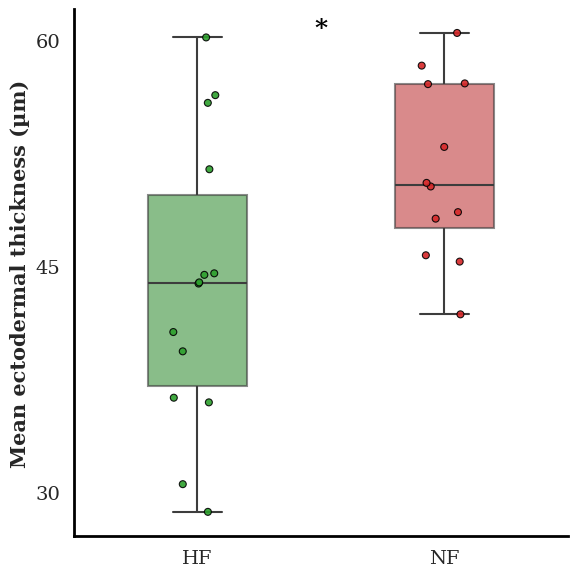

✓ Saved individual vector plot to Ecto_Avg_individual.svg


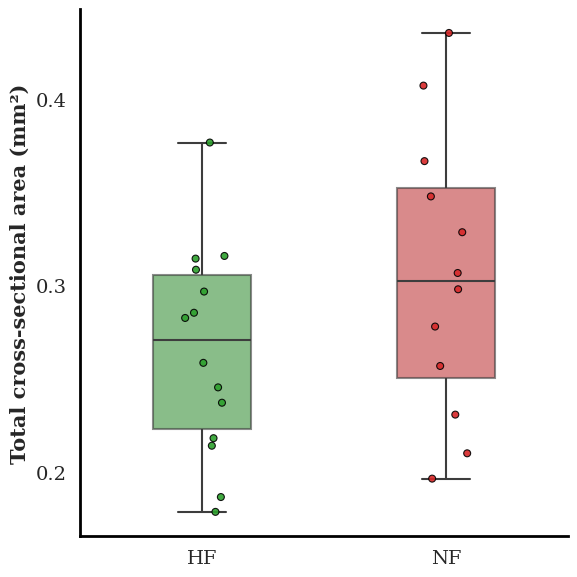

✓ Saved individual vector plot to Total_Area_mm2_individual.svg


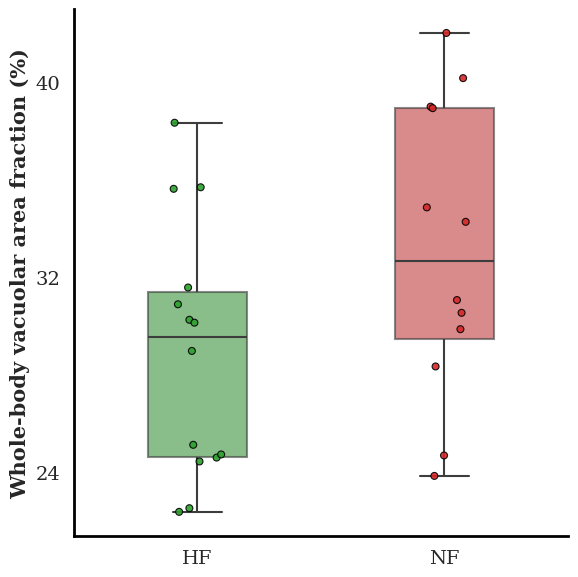

✓ Saved individual vector plot to Vacuole_Percentage_Total_individual.svg


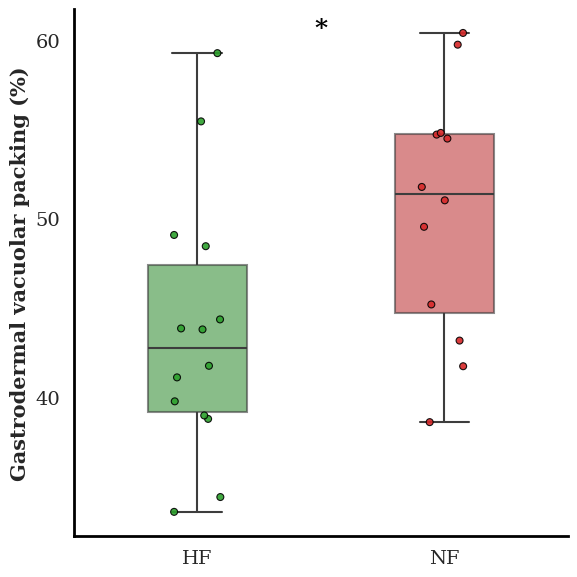

✓ Saved individual vector plot to Vacuole_Percentage_Endoderm_individual.svg


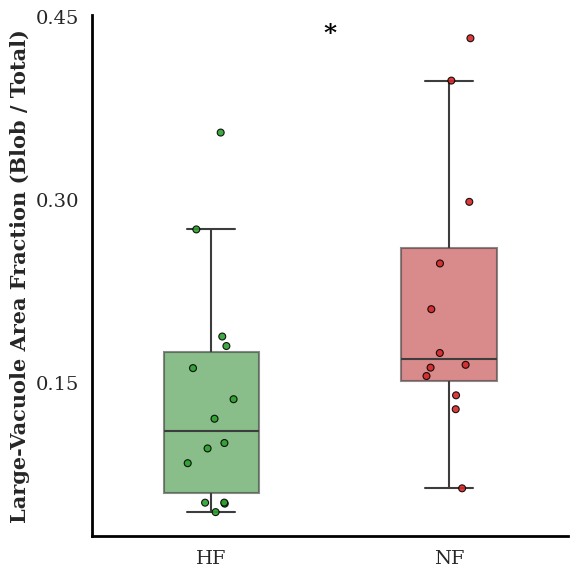

✓ Saved individual vector plot to Large_Vacuole_Area_Fraction_individual.svg


In [31]:
# =========================================================================
# BLOCK 6: HIGH-RESOLUTION INDIVIDUAL PLOT LOOP (600 DPI)
# =========================================================================
import os

y_label_dictionary_fixed = {
    'Ecto_Avg': 'Mean ectodermal thickness (µm)',
    'Total_Area_mm2': 'Total cross-sectional area (mm²)',
    'Vacuole_Percentage_Total': 'Whole-body vacuolar area fraction (%)',
    'Vacuole_Percentage_Endoderm': 'Gastrodermal vacuolar packing (%)',
    'Large_Vacuole_Area_Fraction': 'Large-Vacuole Area Fraction (Blob / Total)'
}

for metric in metrics_to_test:
    # 1. Local Statistical Calculation to prevent global namespace leaks
    hf_sub = master_df[master_df['Morph'] == 'HF'][metric].dropna()
    nf_sub = master_df[master_df['Morph'] == 'NF'][metric].dropna()

    # Check normality locally to decide on the appropriate test
    _, hf_p_sh = stats.shapiro(hf_sub) if len(hf_sub) >= 3 else (0, 0)
    _, nf_p_sh = stats.shapiro(nf_sub) if len(nf_sub) >= 3 else (0, 0)

    if hf_p_sh > 0.05 and nf_p_sh > 0.05:
        _, p_val = stats.ttest_ind(hf_sub, nf_sub, equal_var=False)
    else:
        _, p_val = stats.mannwhitneyu(hf_sub, nf_sub, alternative='two-sided')

    # 2. Plot setup conforming to global styling metrics
    fig, ax = plt.subplots(figsize=global_fig_size)

    sns.boxplot(
        ax=ax,
        data=master_df,
        x='Morph',
        y=metric,
        hue='Morph',
        order=morph_order,
        palette=variant_colors,
        width=global_box_width,
        fliersize=0,
        linewidth=global_line_width,
        boxprops=dict(alpha=global_alpha),
        legend=False
    )

    sns.stripplot(
        ax=ax,
        data=master_df,
        x='Morph',
        y=metric,
        hue='Morph',
        order=morph_order,
        palette=variant_colors,
        size=global_marker_size,
        alpha=0.9,
        jitter=global_jitter,
        edgecolor=global_edgecolor,
        linewidth=0.8,
        legend=False
    )

    # No individual main titles as requested
    ax.set_title("")

    # Axes Label Uniformity: Y-axis has property and units; X-axis remains blank
    ax.set_ylabel(y_label_dictionary_fixed[metric])
    ax.set_xlabel("")

    ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=global_y_nbins))

    # Dynamic significance labelling via global helper
    sig_label = get_significance_label(p_val)
    if sig_label != 'n.s.':
        ymin, ymax = ax.get_ylim()
        ax.text(
            0.5,
            ymax - (ymax - ymin) * 0.05,
            sig_label,
            horizontalalignment='center',
            fontsize=global_asterisk_size,
            color='black',
            weight=global_asterisk_weight
        )

    sns.despine(ax=ax)
    plt.tight_layout()

    # Save figure as high resolution vector SVG
    filename = f"{metric}_individual.svg"
    plt.savefig(filename, format='svg', dpi=600)
    plt.show()
    print(f"✓ Saved individual vector plot to {filename}")

### Block 7: Multi-Panel Publication Summary Figure
This block aggregates all five physiological metrics into a single high-resolution panel for comparative analysis.

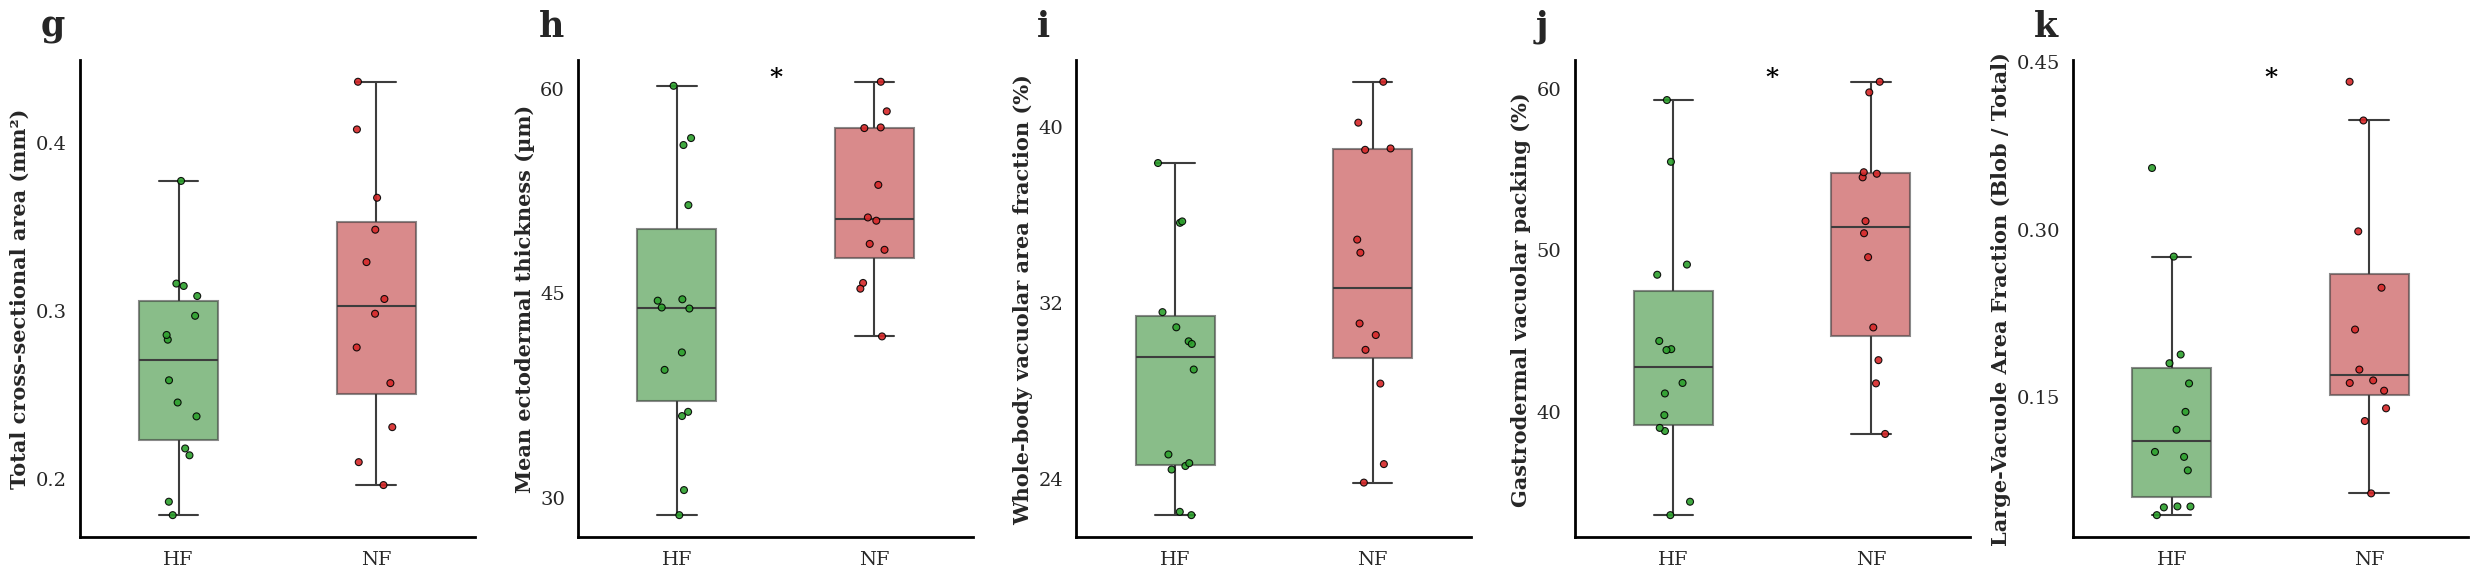

✓ Saved 5-panel summary figure to png, tiff, and svg formats.


In [32]:
import string

# =========================================================================
# BLOCK 7: COMBINED 5-PANEL SUMMARY FIGURE (600 DPI)
# =========================================================================

combined_order = [
    'Total_Area_mm2',
    'Ecto_Avg',
    'Vacuole_Percentage_Total',
    'Vacuole_Percentage_Endoderm',
    'Large_Vacuole_Area_Fraction'
]

fig, axes = plt.subplots(1, 5, figsize=(25, 6))

# Dynamic internal update dictionary
y_label_dictionary_fixed = {
    'Ecto_Avg': 'Mean ectodermal thickness (µm)',
    'Total_Area_mm2': 'Total cross-sectional area (mm²)',
    'Vacuole_Percentage_Total': 'Whole-body vacuolar area fraction (%)',
    'Vacuole_Percentage_Endoderm': 'Gastrodermal vacuolar packing (%)',
    'Large_Vacuole_Area_Fraction': 'Large-Vacuole Area Fraction (Blob / Total)'
}

for i, metric in enumerate(combined_order):
    ax = axes[i]

    # 1. Local Statistical Calculation to prevent namespace leaks
    hf_sub = master_df[master_df['Morph'] == 'HF'][metric].dropna()
    nf_sub = master_df[master_df['Morph'] == 'NF'][metric].dropna()

    # Check normality locally to choose the statistical test
    _, hf_p_sh = stats.shapiro(hf_sub) if len(hf_sub) >= 3 else (0, 0)
    _, nf_p_sh = stats.shapiro(nf_sub) if len(nf_sub) >= 3 else (0, 0)

    if hf_p_sh > 0.05 and nf_p_sh > 0.05:
        _, p_val = stats.ttest_ind(hf_sub, nf_sub, equal_var=False)
    else:
        _, p_val = stats.mannwhitneyu(hf_sub, nf_sub, alternative='two-sided')

    # 2. Plot setup conforming to global styling metrics
    sns.boxplot(
        ax=ax,
        data=master_df,
        x='Morph',
        y=metric,
        hue='Morph',
        order=morph_order,
        palette=variant_colors,
        width=global_box_width,
        fliersize=0,
        linewidth=global_line_width,
        boxprops=dict(alpha=global_alpha),
        legend=False
    )

    sns.stripplot(
        ax=ax,
        data=master_df,
        x='Morph',
        y=metric,
        hue='Morph',
        order=morph_order,
        palette=variant_colors,
        size=global_marker_size,
        alpha=0.9,
        jitter=global_jitter,
        edgecolor=global_edgecolor,
        linewidth=0.8,
        legend=False
    )

    # No individual main titles as requested
    ax.set_title("")

    # Axis labels styling rules
    ax.set_ylabel(y_label_dictionary_fixed[metric])
    ax.set_xlabel('')

    ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=global_y_nbins))
    sns.despine(ax=ax)

    # Add panel letters starting with 'g'
    ax.text(-0.1, 1.05, string.ascii_lowercase[i+6], transform=ax.transAxes, size=25, weight='bold')

    # Dynamic significance labelling via global helper
    sig_label = get_significance_label(p_val)
    if sig_label != 'n.s.':
        ymin, ymax = ax.get_ylim()
        ax.text(
            0.5,
            ymax - (ymax - ymin) * 0.05,
            sig_label,
            horizontalalignment='center',
            fontsize=global_asterisk_size,
            color='black',
            weight=global_asterisk_weight
        )

plt.tight_layout()
plt.show()

fig.savefig("Histology_Morphometrics_and_Lipids.png", dpi=600, bbox_inches='tight')
fig.savefig("Histology_Morphometrics_and_Lipids.tiff", dpi=600, bbox_inches='tight')
fig.savefig("Histology_Morphometrics_and_Lipids.svg", dpi=600, bbox_inches='tight')
print("✓ Saved 5-panel summary figure to png, tiff, and svg formats.")

### Block 8: Detailed Statistical Report
This block generates a formatted summary of all physiological metrics, providing the raw values and test statistics used in the publication figures.

In [33]:
import pandas as pd
import numpy as np
import scipy.stats as stats

# --- DETAILED STATISTICAL REPORT GENERATOR WITH EFFECT SIZES & CONFIDENCE INTERVALS ---
stats_report = []

def run_stat_and_get_metrics(hf_data, nf_data, metric_name, sensitivity=False):
    # 1. Descriptive Strings: Mean ± SD [Median]
    desc_hf = f"{hf_data.mean():.4f} ± {hf_data.std():.4f} [{hf_data.median():.4f}]"
    desc_nf = f"{nf_data.mean():.4f} ± {nf_data.std():.4f} [{nf_data.median():.4f}]"

    # 2. Shapiro-Wilk Normality test
    _, hf_p = stats.shapiro(hf_data) if len(hf_data) >= 3 else (0, 0)
    _, nf_p = stats.shapiro(nf_data) if len(nf_data) >= 3 else (0, 0)
    is_normal = (hf_p > 0.05) and (nf_p > 0.05)

    # 3. Core Hypothesis Testing & Effect Size Computations
    n_hf, n_nf = len(hf_data), len(nf_data)

    if is_normal:
        test_used = "Welch's Parametric T-Test"
        stat, p_val = stats.ttest_ind(hf_data, nf_data, equal_var=False)

        # Cohen's d computation
        var_hf, var_nf = hf_data.var(ddof=1), nf_data.var(ddof=1)
        s_pooled = np.sqrt(((n_hf - 1) * var_hf + (n_nf - 1) * var_nf) / (n_hf + n_nf - 2))
        cohens_d = (hf_data.mean() - nf_data.mean()) / s_pooled if s_pooled != 0 else 0

        # Cohen's d 95% Confidence Interval
        se_d = np.sqrt(((n_hf + n_nf) / (n_hf * n_nf)) + (cohens_d**2 / (2 * (n_hf + n_nf))))
        ci_lower = cohens_d - 1.96 * se_d
        ci_upper = cohens_d + 1.96 * se_d

        effect_size_str = f"Cohen's d: {cohens_d:.4f} (95% CI: [{ci_lower:.4f}, {ci_upper:.4f}])"
    else:
        test_used = "Non-Parametric Mann-Whitney U"
        stat, p_val = stats.mannwhitneyu(hf_data, nf_data, alternative='two-sided')

        # Rank-Biserial Correlation (r) computation
        # r = 1 - (2 * U / (n1 * n2))
        rank_biserial = 1 - (2 * stat / (n_hf * n_nf)) if (n_hf * n_nf) != 0 else 0
        effect_size_str = f"Rank-Biserial r: {rank_biserial:.4f}"

    return {
        'Metric': f"{metric_name} (Sensitivity Check - IQR Pruned)" if sensitivity else metric_name,
        'HF_Descriptive_Stats': desc_hf,
        'HF_N': n_hf,
        'NF_Descriptive_Stats': desc_nf,
        'NF_N': n_nf,
        'Test_Used': test_used,
        'Test_Statistic': round(stat, 4),
        'P_Value': round(p_val, 4),
        'Significance': "***" if p_val < 0.001 else ("**" if p_val < 0.01 else ("*" if p_val < 0.05 else "ns")),
        'Effect_Size_Metrics': effect_size_str
    }

# Run metrics on unpruned dataset (N=26)
for metric in metrics_to_test:
    hf_data = master_df[master_df['Morph'] == 'HF'][metric].dropna()
    nf_data = master_df[master_df['Morph'] == 'NF'][metric].dropna()
    stats_report.append(run_stat_and_get_metrics(hf_data, nf_data, title_dictionary[metric], sensitivity=False))

# Run sensitivity row on 1.5x IQR Pruned Large_Vacuole_Area_Fraction (N=24)
pruned_df = prune_group_outliers(master_df, 'Morph', 'Large_Vacuole_Area_Fraction')
hf_pruned = pruned_df[pruned_df['Morph'] == 'HF']['Large_Vacuole_Area_Fraction'].dropna()
nf_pruned = pruned_df[pruned_df['Morph'] == 'NF']['Large_Vacuole_Area_Fraction'].dropna()
stats_report.append(run_stat_and_get_metrics(hf_pruned, nf_pruned, title_dictionary['Large_Vacuole_Area_Fraction'], sensitivity=True))

df_stats_summary = pd.DataFrame(stats_report)

print("=========================================================================")
print("📜 FULL PUBLICATION STATISTICAL SUMMARY (with Effect Sizes)")
print("=========================================================================")
display(df_stats_summary)

df_stats_summary.to_csv("histology_statistical_summary.csv", index=False)
print("\n✓ Statistical summary exported to 'histology_statistical_summary.csv'")

📜 FULL PUBLICATION STATISTICAL SUMMARY (with Effect Sizes)


,Metric,HF_Descriptive_Stats,HF_N,NF_Descriptive_Stats,NF_N,Test_Used,Test_Statistic,P_Value,Significance,Effect_Size_Metrics
0,Mean ectodermal thickness,43.7071 ± 9.5288 [43.8806],14,51.3489 ± 5.8694 [50.3996],12,Welch's Parametric T-Test,-2.4983,0.0205,*,"Cohen's d: -0.9481 (95% CI: [-1.7610, -0.1351])"
1,Total cross-sectional area,0.2655 ± 0.0561 [0.2705],14,0.3052 ± 0.0759 [0.3023],12,Welch's Parametric T-Test,-1.4947,0.1506,ns,"Cohen's d: -0.6020 (95% CI: [-1.3903, 0.1862])"
2,Whole-body vacuolar area fraction,28.9306 ± 5.1841 [29.5384],14,33.1234 ± 6.0639 [32.6565],12,Welch's Parametric T-Test,-1.8781,0.0738,ns,"Cohen's d: -0.7481 (95% CI: [-1.5455, 0.0493])"
3,Gastrodermal vacuolar packing,43.7329 ± 7.3221 [42.7474],14,50.4204 ± 7.0138 [51.3911],12,Welch's Parametric T-Test,-2.3750,0.0260,*,"Cohen's d: -0.9311 (95% CI: [-1.7426, -0.1196])"
4,Large-vacuole area fraction,0.1350 ± 0.0914 [0.1100],14,0.2141 ± 0.1109 [0.1691],12,Non-Parametric Mann-Whitney U,43.0000,0.0372,*,Rank-Biserial r: 0.4881
5,Large-vacuole area fraction (Sensitivity Check...,0.1181 ± 0.0687 [0.1001],13,0.1943 ± 0.0914 [0.1642],11,Welch's Parametric T-Test,-2.2738,0.0352,*,"Cohen's d: -0.9544 (95% CI: [-1.8015, -0.1073])"



✓ Statistical summary exported to 'histology_statistical_summary.csv'


### Block 9: Software Versions & Reproducibility
This block logs the specific versions of the software environment used to generate these results, ensuring consistent behavior for future re-analysis.

In [34]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import scipy

# --- SOFTWARE VERSION REPORT ---
print("=========================================================================")
print("🛠️ ANALYSIS REPRODUCIBILITY LOG")
print("=========================================================================")
print(f"Python Version:   {sys.version.split(' ')[0]}")
print(f"Pandas Version:   {pd.__version__}")
print(f"NumPy Version:    {np.__version__}")
print(f"SciPy Version:    {scipy.__version__}")
print(f"Matplotlib:       {matplotlib.__version__}")
print(f"Seaborn Version:  {sns.__version__}")
print("=========================================================================")

🛠️ ANALYSIS REPRODUCIBILITY LOG
Python Version:   3.13.18
Pandas Version:   2.2.3
NumPy Version:    2.4.6
SciPy Version:    1.16.3
Matplotlib:       3.10.0
Seaborn Version:  0.13.2


### Block 9: Outlier Report
This block generates a detailed report of all data points identified and removed as outliers by the `prune_group_outliers` function for each metric, grouped by morphotype.

In [35]:
outlier_report_data = []

for metric in metrics_to_test:
    original_df = master_df[['Morph', metric]].copy()
    cleaned_df = prune_group_outliers(master_df, 'Morph', metric)

    for morph_type in ['HF', 'NF']:
        original_morph_data = original_df[original_df['Morph'] == morph_type]
        cleaned_morph_data = cleaned_df[cleaned_df['Morph'] == morph_type]

        original_values = set(original_morph_data[metric].values)
        cleaned_values = set(cleaned_morph_data[metric].values)
        outlier_values = list(original_values - cleaned_values)

        for outlier_val in outlier_values:
            outlier_report_data.append({
                'Metric': title_dictionary[metric],
                'treatment': 'Outlier Extraction',
                'Morph': morph_type,
                'value': outlier_val,
                'reason': 'Removed as 1.5xIQR outlier'
            })

df_outlier_report = pd.DataFrame(outlier_report_data)

print("=========================================================================")
print("📈 OUTLIER EXTRACTION REPORT")
print("=========================================================================")
display(df_outlier_report)
df_outlier_report.to_csv("outlier_report.csv", index=False)

📈 OUTLIER EXTRACTION REPORT


,Metric,treatment,Morph,value,reason
0,Large-vacuole area fraction,Outlier Extraction,HF,0.3546,Removed as 1.5xIQR outlier
1,Large-vacuole area fraction,Outlier Extraction,NF,0.4319,Removed as 1.5xIQR outlier
